# Regression Modeling and Evaluation

## 1. Objective and Scope

The objective of this notebook is to develop and evaluate multiple linear regression models to predict `enade_score` using students' demographic characteristics, socioeconomic indicators, and reading and writing scores.

Three regression approaches are compared:

- **Ordinary Least Squares (Linear Regression):** serves as the baseline model without coefficient regularization.
- **Ridge Regression (L2 regularization):** penalizes large coefficient values to reduce model complexity and potentially improve generalization.
- **Lasso Regression (L1 regularization):** penalizes coefficient magnitudes and can shrink some coefficients to zero, providing a form of feature selection.

The analysis aims to compare predictive performance, examine residual behavior, interpret fitted coefficients, and select a model based on the results obtained from the held-out test set.

## 2. Modeling Workflow

### 2.1. Data Preparation and Train-Test Split

The cleaned dataset produced during the exploratory data analysis is loaded, and the predictors are separated from the target variable. The data are then divided into training and test sets before preprocessing. The test set is reserved for evaluating the fitted models on observations that were not used during training.

### 2.2. Explicit Preprocessing

Preprocessing is performed explicitly, as separate and inspectable steps, rather than being encapsulated in a single modeling pipeline. This approach makes each transformation and its effect on the data easier to examine and understand.

A `ColumnTransformer` is used to apply different transformations according to predictor type:

- **Numerical predictors (`reading_score`, `writing_score`):** `StandardScaler` standardizes the variables using the training-set means and standard deviations. This is particularly important when comparing regularized regression models, because their penalties are sensitive to predictor scale.
- **Categorical predictors:** `OneHotEncoder(drop='first', sparse_output=False)` converts categorical values into binary indicators. Dropping one category per variable avoids perfect linear dependence among the encoded categories when the model includes an intercept.

The preprocessor is fitted on the training data and subsequently applied to the test data without refitting. Keeping preprocessing explicit provides transparency, while fitting transformations only on the training set prevents direct information leakage from the held-out test set.

### 2.3. Model Training and Regularization

The three regression models are fitted using the preprocessed training data. Ridge and Lasso use cross-validation to select their regularization parameters from a predefined grid of candidate values.

The ordinary linear regression model provides a reference for assessing whether regularization offers a meaningful improvement in predictive performance.

### 2.4. Predictive Performance Evaluation

Predictions are generated for the held-out test set and evaluated using three complementary metrics:

- **Mean Absolute Error (MAE):** measures the average absolute prediction error in score points.
- **Root Mean Squared Error (RMSE):** measures prediction error in score points while assigning greater weight to larger errors.
- **Coefficient of Determination (R²):** measures the proportion of target variance explained by the model relative to a mean-prediction baseline.

Lower MAE and RMSE values indicate smaller prediction errors, whereas higher R² values generally indicate better predictive performance on the evaluated dataset.

### 2.5. Residual Diagnostics

Residual plots are examined to assess whether the prediction errors exhibit patterns that may indicate limitations in the linear model. The analysis includes residuals against predicted values, the residual distribution, and a normal Q-Q plot.

These visual diagnostics help investigate linearity, potential heteroscedasticity, and the approximate normality of residuals. They are interpreted as diagnostic evidence rather than as a guarantee that all regression assumptions are satisfied.

### 2.6. Model and Preprocessor Export

The selected regression model and the fitted preprocessor are saved as separate artifacts for subsequent reuse. Keeping both artifacts is necessary to ensure that new observations undergo the same transformations before predictions are generated.


In [ ]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV

from src.config import CLEAN_DATA_PATH, MODEL, PREPROCESSOR
from src.model import evaluate_model, plot_residual_analysis

## 2. Data Preparation and Train-Test Split

This section loads the cleaned dataset, separates the target variable from the predictors, identifies numerical and categorical features, and creates the training and test sets. The split is performed before preprocessing to preserve the test set for independent model evaluation.

In [2]:
df = pd.read_parquet(CLEAN_DATA_PATH)

df.head()

,sex,race/ethnicity,parental_level_of_education,lunch,test_preparation_course,enade_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   sex                          999 non-null    str  
 1   race/ethnicity               999 non-null    str  
 2   parental_level_of_education  999 non-null    str  
 3   lunch                        999 non-null    str  
 4   test_preparation_course      999 non-null    str  
 5   enade_score                  999 non-null    int16
 6   reading_score                999 non-null    int16
 7   writing_score                999 non-null    int16
dtypes: int16(3), str(5)
memory usage: 85.8 KB


In [4]:
X = df.drop(columns=['enade_score'])
y = df['enade_score']

In [5]:
numerical_cols = [col for col in X.select_dtypes('int16')]

categorical_cols = [col for col in X.columns if col not in numerical_cols]

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### 2.2. Explicit Preprocessing

The predictors include numerical variables (`reading_score` and `writing_score`) and categorical variables describing students' demographic characteristics and educational conditions. These variable types require different preprocessing strategies before model training.

A `ColumnTransformer` is used to apply the appropriate transformation to each group of predictors:

- **Numerical features:** `StandardScaler` standardizes the numerical variables by removing their means and scaling them to unit variance. This is particularly relevant for Ridge and Lasso regression, whose regularization penalties are sensitive to feature scales.
- **Categorical features:** `OneHotEncoder` converts categorical variables into numerical indicator columns. Setting `drop='first'` removes one category per variable to establish a reference category and avoid redundant dummy-variable representations.

The preprocessor is fitted using the training data and then applied to both the training and test sets. This ensures that the test data do not influence the estimated scaling parameters or the categorical encoding learned during preprocessing.

In [7]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_cols)
    ]
)

In [8]:
X_train_processed = pd.DataFrame(
    preprocessor.fit_transform(X_train),
    columns=preprocessor.get_feature_names_out(),
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    preprocessor.transform(X_test),
    columns=preprocessor.get_feature_names_out(),
    index=X_test.index
)

X_train_processed.head()

,num__reading_score,num__writing_score,cat__sex_male,cat__race/ethnicity_group B,cat__race/ethnicity_group C,cat__race/ethnicity_group D,cat__race/ethnicity_group E,cat__parental_level_of_education_bachelor's degree,cat__parental_level_of_education_high school,cat__parental_level_of_education_master's degree,cat__parental_level_of_education_some college,cat__parental_level_of_education_some high school,cat__lunch_standard,cat__test_preparation_course_none
778,1.096136,0.921895,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
286,1.372964,0.921895,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0
165,-1.256897,-1.141208,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
960,-1.049276,-1.008104,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
493,-0.357208,-0.009829,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0


### 2.3. Model Training and Hyperparameter Selection

Three multiple linear regression models are evaluated: ordinary linear regression, Ridge regression, and Lasso regression. The models use the same training and test partitions and the same preprocessed predictors, allowing their predictive performance to be compared under consistent data conditions.

Ordinary linear regression serves as the baseline model. Ridge and Lasso introduce regularization to assess whether penalizing coefficient magnitudes improves predictive performance.

__________________________________________________________________________________________________________________________

Ridge and Lasso require the selection of a regularization parameter, `alpha`. A logarithmically spaced grid of candidate values is defined, and five-fold cross-validation is used for hyperparameter selection.

Ordinary linear regression does not require this parameter and is fitted directly to the training data.

The preprocessing and cross-validation procedures are kept explicit in separate steps for readability. One methodological limitation is that the preprocessor is fitted on the complete training set before the internal cross-validation used by Ridge and Lasso. Consequently, the preprocessing parameters are not independently estimated within each cross-validation fold.

In [9]:
alphas_grid = np.logspace(-3, 3, 100)

In [10]:
linear_regression = LinearRegression()
ridge_cv = RidgeCV(alphas=alphas_grid, cv=5)
lasso_cv = LassoCV(alphas=alphas_grid, cv=5, random_state=42)

In [11]:
linear_regression.fit(X_train_processed, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](14,)","[ 3.77,10.62,13.27,..., 0.82, 3.42, 3.42]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](14,)","['num__reading_score','num__writing_score','cat__sex_male',..., 'cat__parental_level_of_education_some high school','cat__lunch_standard', 'cat__test_preparation_course_none']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,54.5
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,14
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(14)


In [12]:
ridge_cv.fit(X_train_processed, y_train)


,"alphas alphas: array-like of shape (n_alphas,), default=(0.1, 1.0, 10.0)Array of alpha values to try.Regularization strength; must be a positive float. Regularizationimproves the conditioning of the problem and reduces the variance ofthe estimates. Larger values specify stronger regularization.Alpha corresponds to ``1 / (2C)`` in other linear models such as:class:`~sklearn.linear_model.LogisticRegression` or:class:`~sklearn.svm.LinearSVC`.If using Leave-One-Out cross-validation, alphas must be strictly positive.For an example on how regularization strength affects the model coefficients,see :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`.",array([1.0000...00000000e+03])
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the efficient Leave-One-Out cross-validation- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used, else,:class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.",5
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"scoring scoring: str, callable, default=NoneThe scoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: negative :ref:`mean squared error <mean_squared_error>` if cv is None (i.e. when using leave-one-out cross-validation), or :ref:`coefficient of determination <r2_score>` (:math:`R^2`) otherwise.",None
,"gcv_mode gcv_mode: {'auto', 'svd', 'eigen'}, default='auto'Flag indicating which strategy to use when performingLeave-One-Out Cross-Validation. Options are:: 'auto' : same as 'eigen' 'svd' : use singular value decomposition of X when X is dense, fallback to 'eigen' when X is sparse 'eigen' : use eigendecomposition of X X' when n_samples <= n_features or X' X when n_features < n_samplesThe 'auto' mode is the default and is intended to pick the cheaperoption depending on the shape and sparsity of the training data.",None
,"store_cv_results store_cv_results: bool, default=FalseFlag indicating if the cross-validation values corresponding toeach alpha should be stored in the ``cv_results_`` attribute (seebelow). This flag is only compatible with ``cv=None`` (i.e. usingLeave-One-Out Cross-Validation)... versionchanged:: 1.5 Parameter name changed from `store_cv_values` to `store_cv_results`.",False
,"alpha_per_target alpha_per_target: bool, default=FalseFlag indicating whether to optimize the alpha value (picked from the`alphas` parameter list) for each target separately (for multi-outputsettings: multiple prediction targets). When set to `True`, afterfitting, the `alpha_` attribute will contain a value for each target.When set to `False`, a single alpha is used for all targets.This flag is only compatible with ``cv=None`` (i.e. usingLeave-One-Out Cross-Validation)... versionadded:: 0.24",False
Name,Type,Value
"alpha_ alpha_: float or ndarray of shape (n_targets,)Estimated regularization parameter, or, if ``alpha_per_target=True``,the estimated regularization parameter for each target.",float64,1.63
"best_score_ best_score_: float or ndarray of shape (n_targets,)Score of base estimator with best alpha, or, if``alpha_per_target=True``, a score for each target... versionadded:: 0.23",float64,0.8636
"coef_ coef_: ndarray of shape (n_features) or (n_targets, n_features)Weight vector(s).","ndarray[float64](14,)","[ 4.01,10.32,13.09,..., 0.76, 3.45, 3.3 ]"


In [13]:
lasso_cv.fit(X_train_processed, y_train)

,"alphas alphas: array-like or int, default=100Values of alphas to test along the regularization path.If int, `alphas` values are generated automatically.If array-like, list of alpha values to use... versionchanged:: 1.7 `alphas` accepts an integer value which removes the need to pass `n_alphas`.",array([1.0000...00000000e+03])
,"cv cv: int, cross-validation generator or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- int, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For int/None inputs, :class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"eps eps: float, default=1e-3Length of the path. ``eps=1e-3`` means that``alpha_min / alpha_max = 1e-3``.",0.001
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: 'auto', bool or array-like of shape (n_features, n_features), default='auto'Whether to use a precomputed Gram matrix to speed upcalculations. If set to ``'auto'`` let us decide. The Grammatrix can also be passed as an argument.",'auto'
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``.",0.0001
,"copy_X copy_X: bool, default=TrueIf ``True``, `X` will be copied; otherwise, it may be overwritten.",True
,"verbose verbose: bool or int, default=FalseAmount of verbosity.",False
,"n_jobs n_jobs: int, default=NoneNumber of CPUs to use during the cross validation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None


### 2.4 Predictive Performance Evaluation

The fitted models are evaluated on the held-out test set, which was not used to estimate their coefficients. Three complementary metrics are used:

- **Coefficient of determination (R²):** measures the proportion of target variance explained by the model. Higher values indicate a better fit relative to predicting the target mean.
- **Mean Absolute Error (MAE):** measures the average absolute difference between observed and predicted scores. Lower values indicate smaller average prediction errors.
- **Root Mean Squared Error (RMSE):** measures the square root of the average squared prediction errors, giving greater weight to larger errors. Lower values indicate better predictive performance.

Using multiple metrics provides a broader assessment of predictive performance than relying on a single measure.

In [14]:
y_pred_lr = linear_regression.predict(X_test_processed)
y_pred_ridge = ridge_cv.predict(X_test_processed)
y_pred_lasso = lasso_cv.predict(X_test_processed)

In [15]:
print(f" {5*'-'} Linear Regression {5*'-'}")
_ = evaluate_model(y_test, y_pred_lr)

print(f" {5*'-'} Ridge {5*'-'}")
_ = evaluate_model(y_test, y_pred_ridge)

print(f" {5*'-'} Lasso {5*'-'}")
_ = evaluate_model(y_test, y_pred_lasso)


 ----- Linear Regression -----
Model Evaluation
R² (R-squared): 0.8895
MAE (Mean Absolute Error): 3.92
RMSE (Root Mean Square Error): 4.93
 ----- Ridge -----
Model Evaluation
R² (R-squared): 0.8894
MAE (Mean Absolute Error): 3.93
RMSE (Root Mean Square Error): 4.93
 ----- Lasso -----
Model Evaluation
R² (R-squared): 0.8896
MAE (Mean Absolute Error): 3.93
RMSE (Root Mean Square Error): 4.93


### 2.5 Residual Diagnostics

Residual analysis is used to investigate aspects of model fit that are not fully captured by aggregate performance metrics. The residual plots are examined to identify potential systematic patterns, changes in residual variability, deviations from an approximately normal distribution, and observations with unusually large errors.

These diagnostics complement the test-set metrics and help assess whether the models capture the main patterns in the data. Departures from the expected residual patterns should be interpreted as diagnostic evidence rather than as automatic grounds for rejecting a model.

 ----- Linear Regression -----


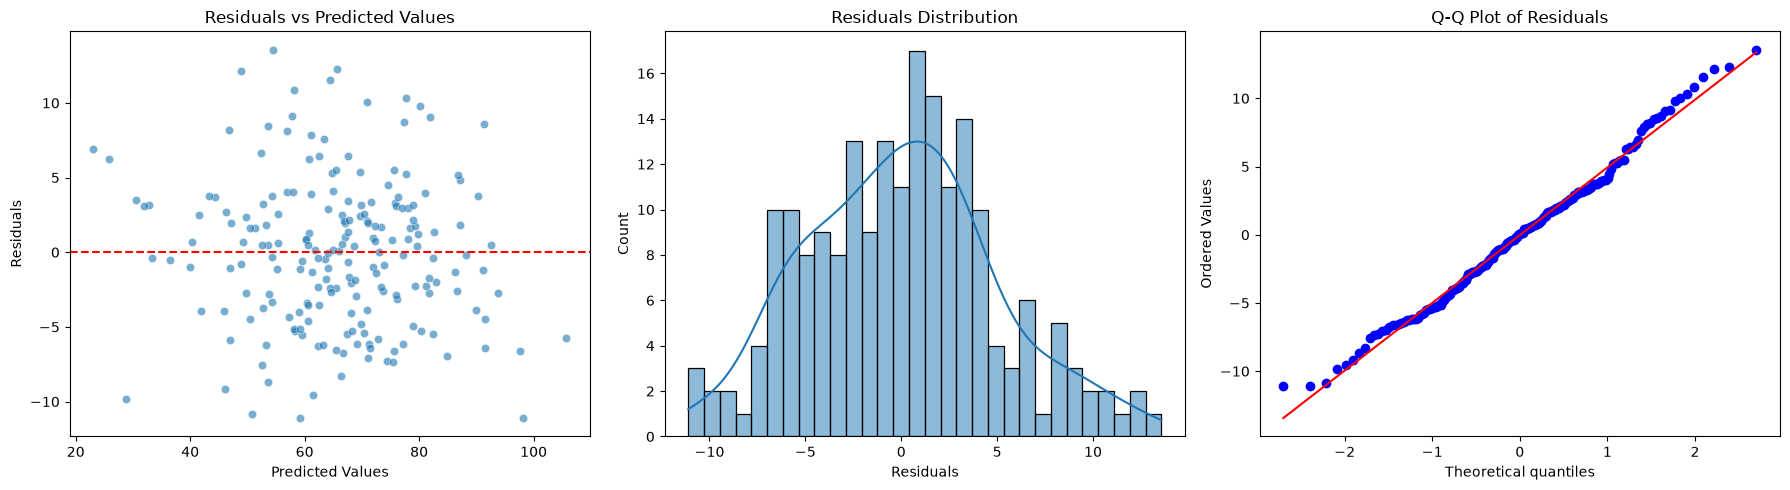

 ----- Ridge -----


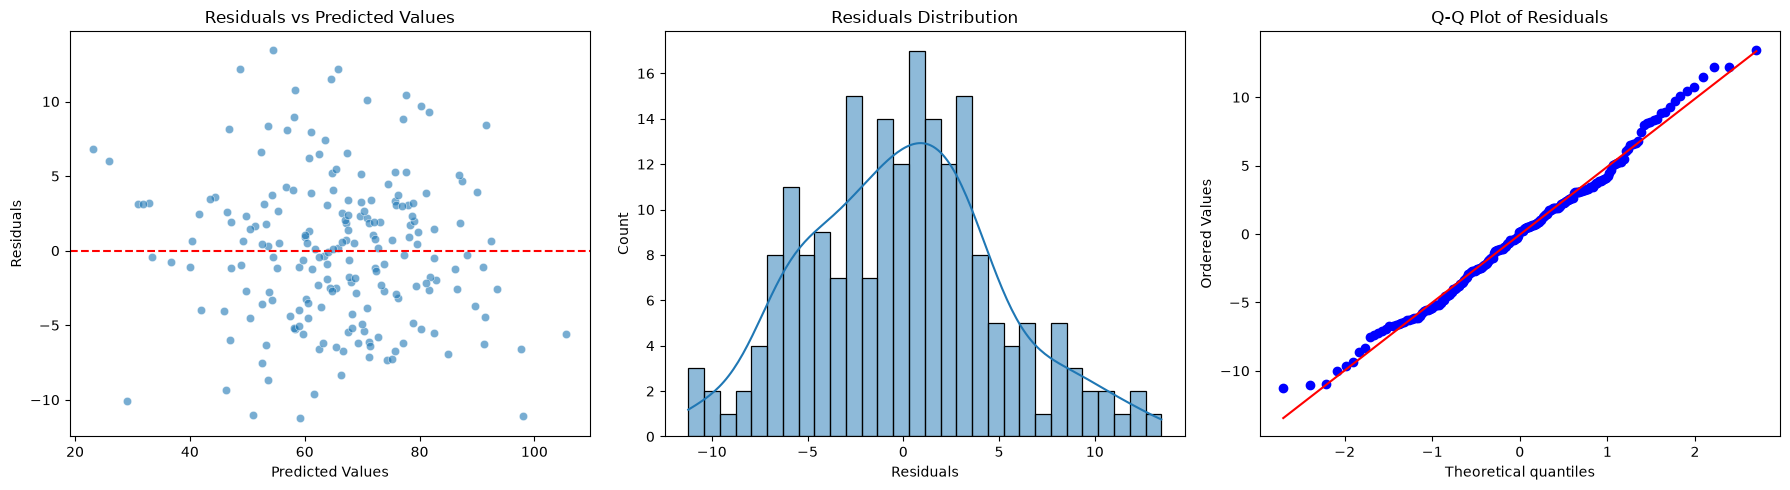

 ----- Lasso -----


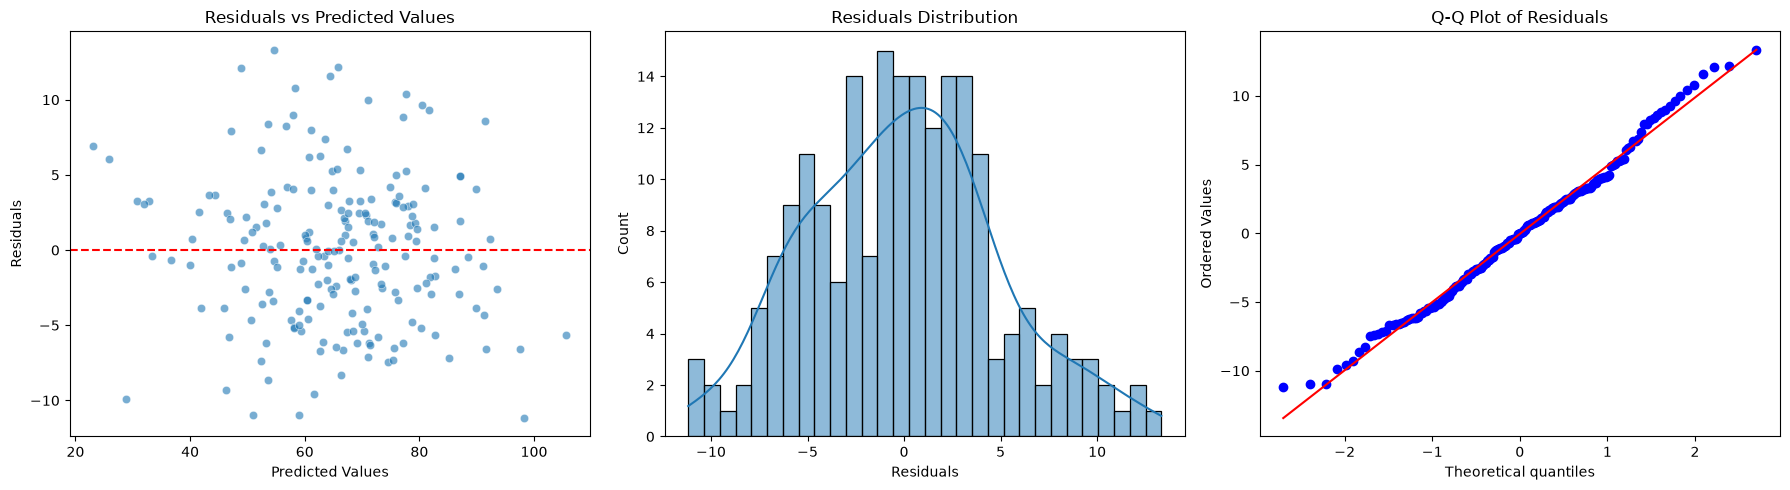

In [16]:
print(f" {5*'-'} Linear Regression {5*'-'}")
plot_residual_analysis(y_test=y_test, y_pred=y_pred_lr)

print(f" {5*'-'} Ridge {5*'-'}")
plot_residual_analysis(y_test=y_test, y_pred=y_pred_ridge)

print(f" {5*'-'} Lasso {5*'-'}")
plot_residual_analysis(y_test=y_test, y_pred=y_pred_lasso)


### 3.3. Residual Diagnostics

Residual diagnostics were performed for Linear Regression, Ridge Regression, and Lasso Regression to assess the patterns of prediction errors and identify potential departures from the assumptions commonly associated with linear regression.

#### Linear Regression

The residuals-versus-predicted-values plot shows residuals distributed around the zero reference line, without a clear systematic curvature. This suggests that the model captures the main linear relationships in the data. However, the spread of residuals appears somewhat variable across the range of predicted values, and some observations exhibit relatively large errors. These patterns warrant caution when assessing the constant-variance assumption.

The residual distribution is approximately unimodal, with some asymmetry and observations in the tails. In the Q-Q plot, most points follow the theoretical reference line reasonably well, particularly in the central region, while deviations become more noticeable at the extremes. This indicates that the residuals are not perfectly normally distributed, although the departure from normality is not pronounced across the entire distribution.

#### Ridge Regression

The Ridge residual plots exhibit patterns very similar to those observed for Linear Regression. Residuals remain distributed around zero without a clear nonlinear pattern, and the residual distribution and Q-Q plot show comparable shapes and tail deviations.

These similarities are consistent with the nearly identical predictive performance of the two models. In this dataset, Ridge regularization does not appear to produce a substantial change in the residual structure or improve the overall fit in a practically meaningful way.

#### Lasso Regression

The Lasso residual plots also show a pattern comparable to those of Linear Regression and Ridge Regression. The residuals are distributed around zero without an evident systematic curvature, while the histogram suggests an approximately unimodal distribution with some asymmetry. The Q-Q plot follows the reference line through much of its central region but departs from it at the tails.

Therefore, Lasso does not appear to introduce a meaningful improvement in the residual patterns. Its diagnostic results are broadly consistent with those of the other two models.

#### Comparative Assessment

Overall, the three models exhibit similar residual patterns. The residuals-versus-predicted-values plots do not reveal a pronounced nonlinear structure, while the histograms and Q-Q plots suggest approximate, but not perfect, normality of the residuals. Some variation in residual spread and deviations in the distribution tails remain visible.

These findings should be interpreted as diagnostic evidence rather than as definitive statistical tests of the regression assumptions. In particular, the residual plots alone do not establish homoscedasticity or normality, and the absence of a clear pattern does not rule out other forms of model misspecification.

Combined with the test-set metrics, the residual diagnostics indicate that Ridge and Lasso do not provide a clear advantage over the ordinary Linear Regression model in this analysis. Given their comparable predictive performance, retaining Linear Regression as the final model is a reasonable choice based on parsimony.

### 2.6. Model and Preprocessor Export

After comparing the predictive performance and residual patterns of Linear Regression, Ridge Regression, and Lasso Regression, the ordinary Linear Regression model was selected as the final model due to its comparable performance and simpler structure.

The fitted model and preprocessing transformer are saved separately using Joblib. Preserving both objects ensures that new observations can undergo the same preprocessing operations applied during model development before predictions are generated. These saved artifacts will subsequently be used by the prediction API.

In [20]:
joblib.dump(linear_regression, MODEL)
joblib.dump(preprocessor, PREPROCESSOR)
print("Model and preprocessor saved successfully.")

Model and preprocessor saved successfully.
